# Keyword ticks in the CASCA 2025 abstracts

The abstracts in this folder are already in order: scheduled presentations from 7 to 10 May 2025, then unscheduled submissions. This notebook marks seven keywords on that order. A tick means the word appears in the title or the abstract.

Open this notebook from `casca-2025-abstracts/` so it can read `abstracts.csv`.

In [1]:
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("abstracts.csv")
df = pd.read_csv(DATA, encoding="utf-8-sig")
df.insert(0, "order", range(1, len(df) + 1))


def fold(value) -> str:
    """Lowercase and strip accents so French and English stems match."""
    text = "" if pd.isna(value) else str(value)
    text = unicodedata.normalize("NFKD", text)
    text = "".join(ch for ch in text if not unicodedata.combining(ch))
    for dash in ("\u2010", "\u2011", "\u2012", "\u2013", "\u2014", "\u2212"):
        text = text.replace(dash, "-")
    return text.casefold()


df["text"] = (df["title"].fillna("") + "\n" + df["abstract"].fillna("")).map(fold)
n_scheduled = int((df["status"] == "Scheduled").sum())
print(f"{len(df)} abstracts, {n_scheduled} scheduled, {len(df) - n_scheduled} unscheduled")

341 abstracts, 276 scheduled, 65 unscheduled


## What counts as a match

The search covers the title and the abstract. It does not cover the session title, so a themed session does not mark every paper in it. Accents are removed first, so *décolonial* and *racisme* count with the English stems.

- **decolonize** matches `decoloni…` and `de-coloni…`: decolonize, decolonizing, decolonization, decolonial, de-colonial, décolonialité.
- **white supremacy** matches `white supremac…`, including supremacist.
- **anti-** matches a hyphenated `anti-` word, and `anticolonial` written as one word. It does not match anticipate or antiretroviral.
- **colonial** matches `colonial` and compounds built on it: colonialism, postcolonial, settler-colonial, decolonial, anti-colonial.
- **racism** matches racism, racist, racisme, and raciste.
- **systemic** matches `systemic…` and `systémique…`: systemic, systemically, systémique, systémiques.
- **ethnography** matches `ethnograph…` and compounds built on it: ethnography, ethnographic, ethnographer, ethnographies, autoethnography, auto-ethnography, ethnographie, ethnographique.

An abstract can tick more than one row. `decolonial` ticks both decolonize and colonial. `anti-colonial` ticks both anti- and colonial.

`colonization` and `colonize` are a different stem, so they do not tick colonial. `racial`, `racialized`, and `race` do not tick racism. `system`, `systems`, `systematic`, `systematization`, and `système` do not tick systemic. `ethnology` and `ethnologie` do not tick ethnography.

In [2]:
PATTERNS = [
    ("decolonize", re.compile(r"\bde-?coloni\w*")),
    ("white supremacy", re.compile(r"white supremac\w*")),
    ("anti-", re.compile(r"\banti(?:-\w+|colonial\w*)")),
    ("colonial", re.compile(r"\b[\w-]*colonial\w*")),
    ("racism", re.compile(r"\bracis(?:m\w*|t\w*)")),
    ("systemic", re.compile(r"\bsystemi(?:c|que)\w*")),
    ("ethnography", re.compile(r"\b[\w-]*ethnograph\w*")),
]

for name, pattern in PATTERNS:
    df[name] = df["text"].map(lambda text, pattern=pattern: bool(pattern.search(text)))

names = [name for name, _ in PATTERNS]
df["keywords"] = df[names].apply(lambda row: ", ".join(name for name in names if row[name]), axis=1)

print("Forms found")
for name, pattern in PATTERNS:
    forms = sorted({match.group(0) for text in df["text"] for match in pattern.finditer(text)})
    print(f"  {name}: {', '.join(forms) if forms else '(none)'}")

print()
print("Abstracts with a tick")
for name in names:
    print(f"  {name:<16} {int(df[name].sum()):>3}")
n_any = int((df["keywords"] != "").sum())
n_multi = int(df[names].sum(axis=1).ge(2).sum())
print(f"  {'any of these':<16} {n_any:>3}")
print(f"  {'two or more':<16} {n_multi:>3}")

colonize = df["text"].str.contains(r"(?<!de)coloni[sz]", regex=True)
left_out = df.loc[colonize & ~df["colonial"], ["order", "number", "title"]]
print()
print(f"Colonize/colonization without the word colonial: {len(left_out)}")
for row in left_out.itertuples(index=False):
    print(f"  {row.order:>3}  #{row.number}  {row.title}")

racial = df["text"].str.contains(r"\bracial\w*|\brace\b", regex=True)
print(f"Racial, racialized, or race, without racism/racist: {int((racial & ~df['racism']).sum())}")

ethnology = df["text"].str.contains(r"\bethnolog\w*", regex=True)
print(f"Ethnology/ethnologie without ethnography: {int((ethnology & ~df['ethnography']).sum())}")

system_other = df["text"].str.contains(r"\bsystem(?!i(?:c|que))\w*", regex=True)
print(f"System, systems, systematic, or système, without systemic: {int((system_other & ~df['systemic']).sum())}")

Forms found
  decolonize: de-colonial, decolonial, decolonialisms, decolonialite, decolonialize, decolonization, decolonize, decolonized, decolonizes, decolonizing
  white supremacy: white supremacy
  anti-: anti-2slgbtqia, anti-capital, anti-colonial, anti-feminist, anti-neoliberal, anti-oppressive, anticolonial
  colonial: anti-colonial, anticolonial, colonial, coloniales, colonialism, colonialite, coloniality, de-colonial, decolonial, decolonialisms, decolonialite, decolonialize, indigenous-colonial, neo-colonialism, neocolonial, non-colonial, post-colonial, postcolonial, settler-colonial, settler-colonialism
  racism: racism, racist
  systemic: systemic, systemiques
  ethnography: autoethnographic, autoethnographie, autoethnography, ethnographe, ethnographer, ethnographic, ethnographically, ethnographie, ethnographies, ethnographique, ethnographiques, ethnography, paraethnographic

Abstracts with a tick
  decolonize        17
  white supremacy    2
  anti-              8
  colonial

## One plot

Each row is a keyword. Each tick is one abstract, at its place in the published order. The first 276 positions are the scheduled program, split by conference day. The shaded band is the 65 unscheduled submissions.

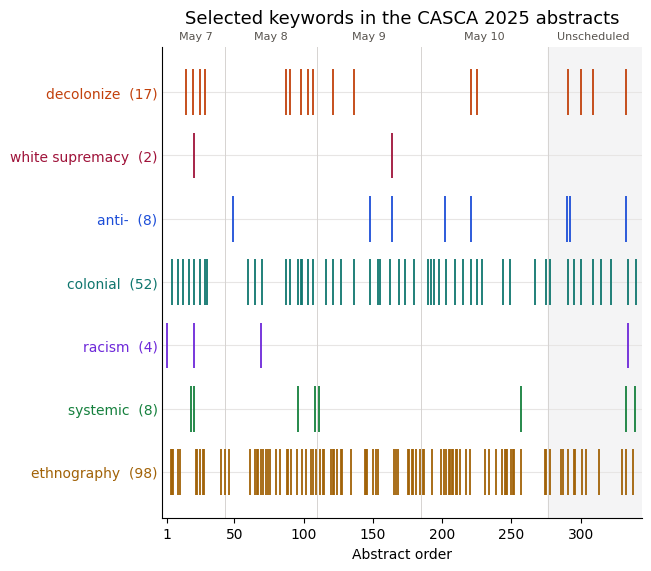

In [3]:
COLORS = {
    "decolonize": "#c2410c",
    "white supremacy": "#9f1239",
    "anti-": "#1d4ed8",
    "colonial": "#0f766e",
    "racism": "#6d28d9",
    "systemic": "#15803d",
    "ethnography": "#a16207",
}

scheduled = df.loc[df["status"] == "Scheduled"].copy()
scheduled["day"] = scheduled["presentation_start_eastern"].str.slice(0, 10)
day_spans = []
for day, group in scheduled.groupby("day", sort=False):
    stamp = pd.Timestamp(day)
    day_spans.append((int(group["order"].iloc[0]), int(group["order"].iloc[-1]), f"{stamp.strftime('%b')} {stamp.day}"))
day_spans.append((n_scheduled + 1, len(df), "Unscheduled"))

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 13,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(6.4, 5.6), layout="constrained")

boundary = n_scheduled + 0.5
pad = 3
ax.axvspan(boundary, len(df) + pad, color="#f4f4f5", zorder=0)
for start, end, _label in day_spans[:-1]:
    ax.axvline(end + 0.5, color="#d6d3d1", lw=0.7, zorder=1)

n_rows = len(names)
offsets = [n_rows - 1 - i for i in range(n_rows)]
for offset, name in zip(offsets, names):
    ax.axhline(offset, color="#e7e5e4", lw=0.8, zorder=0)
    positions = df.loc[df[name], "order"].to_numpy()
    if len(positions):
        ax.eventplot(
            [positions],
            orientation="horizontal",
            lineoffsets=[offset],
            linelengths=0.72,
            linewidths=1.3,
            colors=[COLORS[name]],
            zorder=2,
        )

ax.set_xlim(1 - pad, len(df) + pad)
ax.set_ylim(-0.72, n_rows - 0.28)
ax.set_yticks(offsets)
ax.set_yticklabels([f"{name}  ({int(df[name].sum())})" for name in names])
for label, name in zip(ax.get_yticklabels(), names):
    label.set_color(COLORS[name])
ax.set_xlabel("Abstract order")
ax.set_xticks([1, 50, 100, 150, 200, 250, 300])
ax.set_title("Selected keywords in the CASCA 2025 abstracts")
ax.tick_params(axis="y", length=0)

top = ax.twiny()
top.set_xlim(ax.get_xlim())
top.set_xticks([(start + end) / 2 for start, end, _label in day_spans])
top.set_xticklabels([label for _start, _end, label in day_spans])
top.tick_params(axis="x", length=0, labelsize=8, colors="#57534e")
for spine in top.spines.values():
    spine.set_visible(False)

fig.savefig("keyword-ticks.png", dpi=160)
plt.show()

## Abstracts behind the ticks

Submission number is the program's own number. Order is the position on the plot.

In [4]:
hits = df.loc[
    df["keywords"] != "",
    ["order", "number", "status", "keywords", "session_title", "title"],
].rename(columns={"number": "submission"})
hits.head(100)

,order,submission,status,keywords,session_title,title
0,1,118,Scheduled,racism,Images After the Dead,“I had to keep investigating my visual form of...
3,4,254,Scheduled,ethnography,Organizing Objects Through The Stories We Tell...,Organizing Objects Through The Stories We Tell...
4,5,268,Scheduled,"colonial, ethnography",Conflict and Resistance,Towards an anthropology of the North Borneo di...
5,6,27,Scheduled,ethnography,Global Food Circuits,"Coffee, Neo-Liberal Subjectivities and Tourism..."
8,9,96,Scheduled,"colonial, ethnography",Doing Things with Signs,"The Axe, Long Hair, and Bare Upper Body of Adi..."
...,...,...,...,...,...,...
201,202,67,Scheduled,anti-,"Language, Identity, and Documentation",“City Folk Don’t Get It”: Queer Lives in Rural...
202,203,112,Scheduled,"colonial, ethnography","The Politics of Consultation: Power, Knowledge...",The Consultation Form: Bureaucratic Capture an...
204,205,236,Scheduled,ethnography,Habiter la ville productive : confluences plur...,La ville productive au chevet des cités post-i...
205,206,243,Scheduled,ethnography,Interspecies Confluences I,Wildlife Tracking as Cultural Rewilding Method
